# MEGAN fields from CLM: `EPS_*` and `GAMMA*`

Plain maps of the CLM history fields, time mean over 2001–2014 (annual by default; set `SEASON`).
Rows: isoprene and the 7 monoterpenes that have EPS/GAMMA output (≈ 89 % of MEG_MTERP ≥ 45°N). Columns: EPS, GAMMA, GAMMAL, GAMMAT, GAMMAP, GAMMAA, GAMMAC (isoprene only).

**How CLM writes them** (SourceMod `VOCEmissionMod.F90`): grid-cell values are area means over vegetated patches, including patches that do not emit that compound. So a cell's GAMMA is not emission-weighted, and E ≠ k · EPS · GAMMA in mixed cells.

Colour scale per column shared by all rows and by CTRL and LCC of the same period; EPS has its own scale per compound. Dashed line: modified cells.

In [1]:
import matplotlib.pyplot as plt
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

from boreal_forest_expansion.plotting import megan_maps as mm
from boreal_forest_expansion.plotting.style import set_default_style

set_default_style()

SEASON = "ANN"          # "ANN", "JJA", "MAM", "SON", "DJF"

## PD: CTRL_PD and LCC_PD

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/CTRL_PD_gammas_ANN_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/LCC_PD_gammas_ANN_2001_2014.png


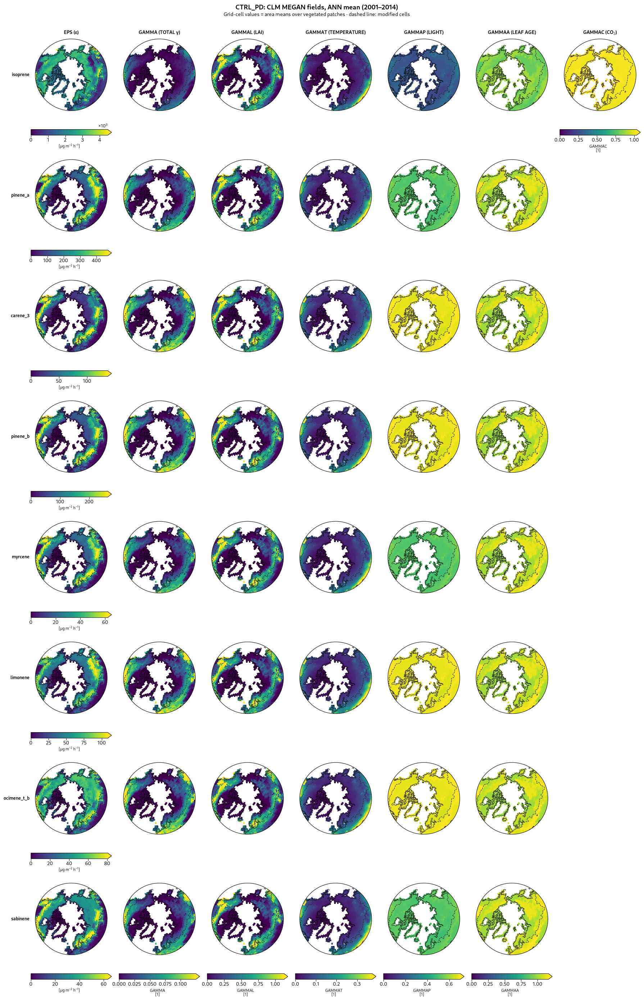

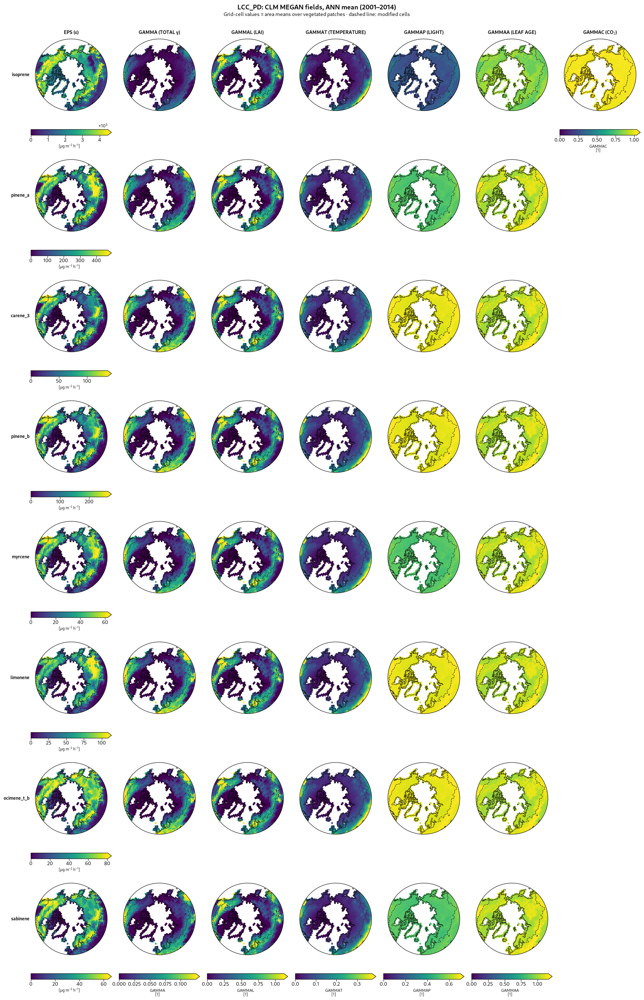

In [2]:
figs = mm.make_gamma_maps("PD", SEASON)

## FUT: CTRL_FUT and LCC_FUT

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/CTRL_FUT_gammas_ANN_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/LCC_FUT_gammas_ANN_2001_2014.png


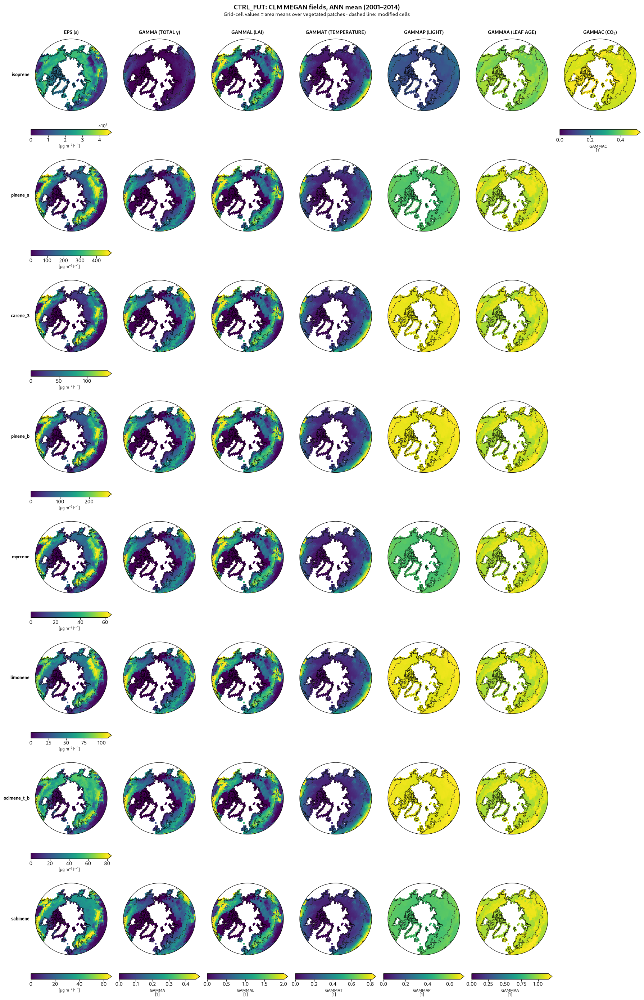

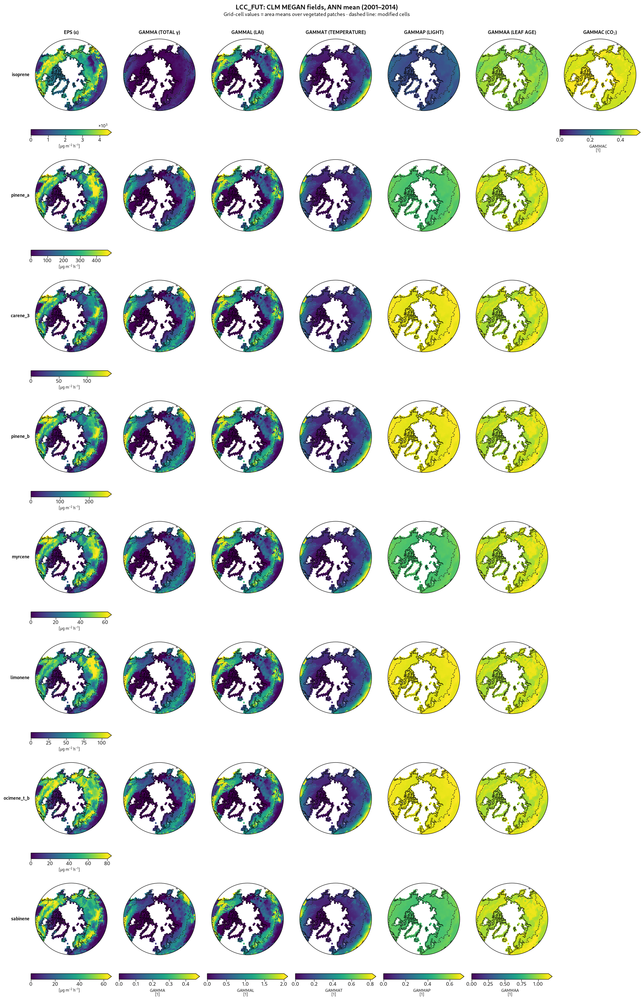

In [3]:
figs = mm.make_gamma_maps("FUT", SEASON)

## Change and attribution, LCC vs CTRL (same period)

PD = `LCC_PD` vs `CTRL_PD`; FUT = `LCC_FUT` vs `CTRL_FUT` (`forcing_maps.BVOC_PAIRS`; fBVOC runs have no MEGAN output).
`mm.make_factor_maps(group, experiment, season)` adds an effective (emission-weighted) γ and the % change LCC vs CTRL; `mm.make_attribution_maps(...)` splits the emission change into factors using log changes (ln E = ln(f·ε) + ln γ_eff, and ln γ_eff ≈ ln γ_L + ln γ_T + … + residual, so the changes add up).
Isoprene and monoterpenes × PD and FUT, annual and JJA (`CHANGE_SEASONS`).

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_isoprene_factors_ANN_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_isoprene_attribution_ANN_2001_2014.png


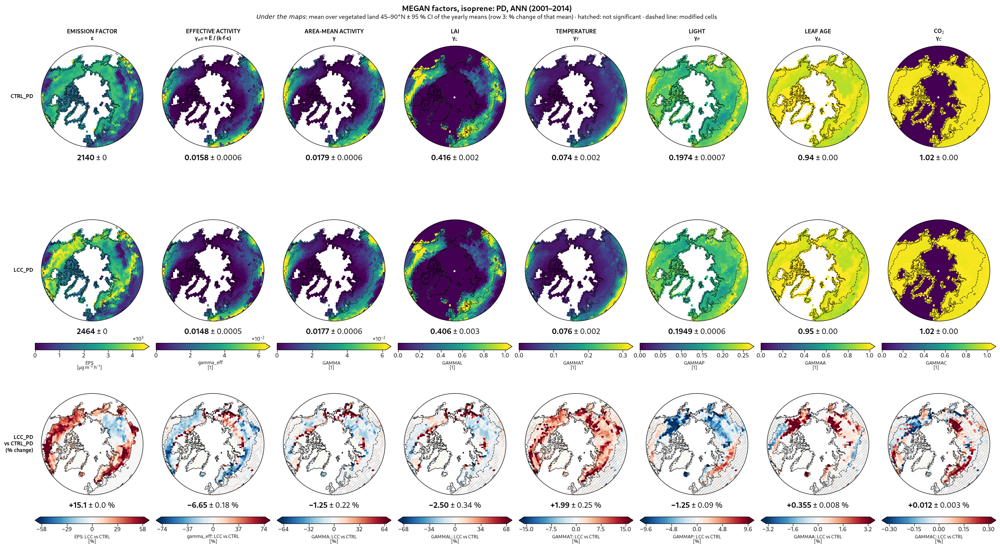

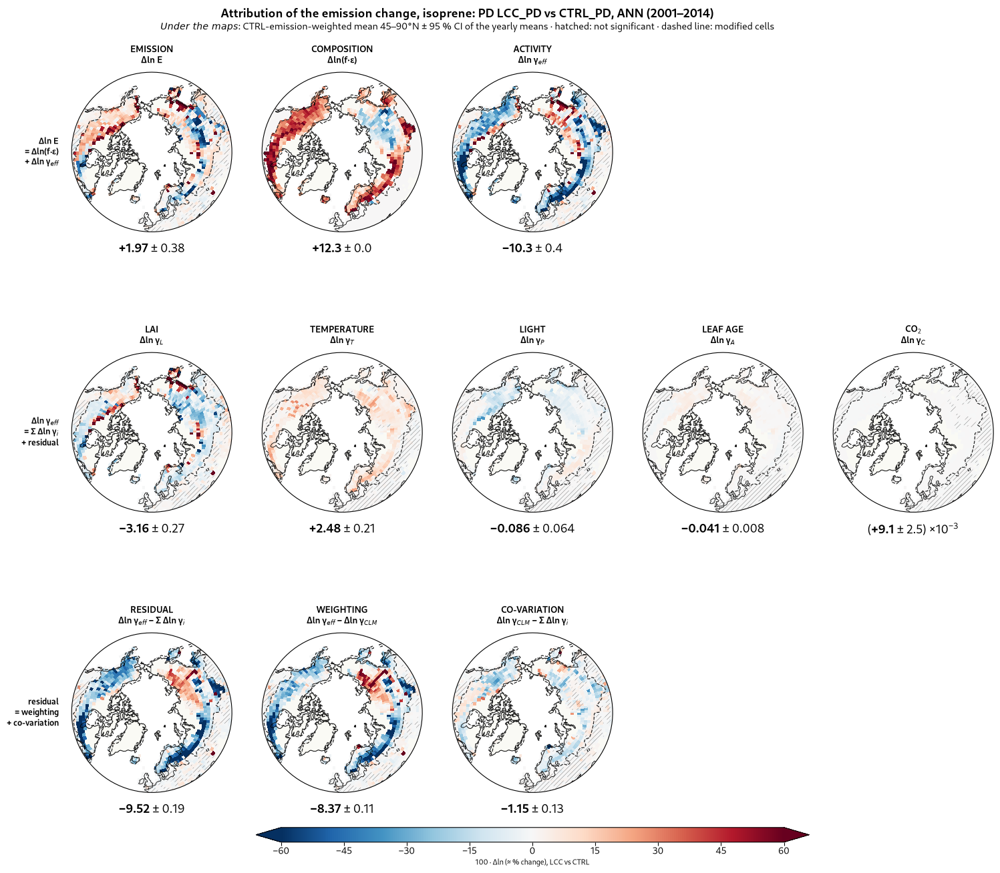

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_MTERP_factors_ANN_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_MTERP_attribution_ANN_2001_2014.png


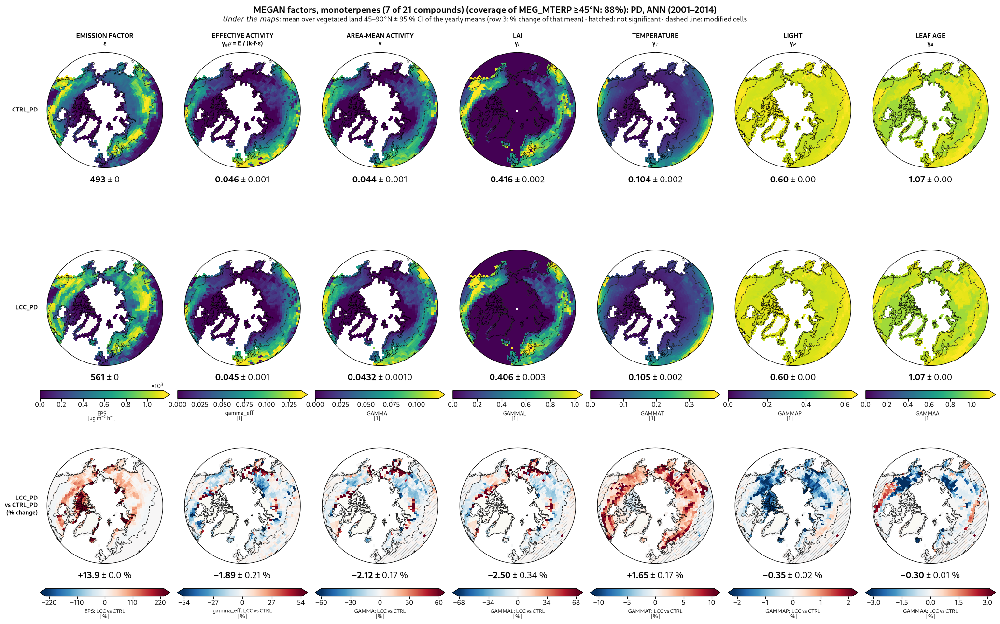

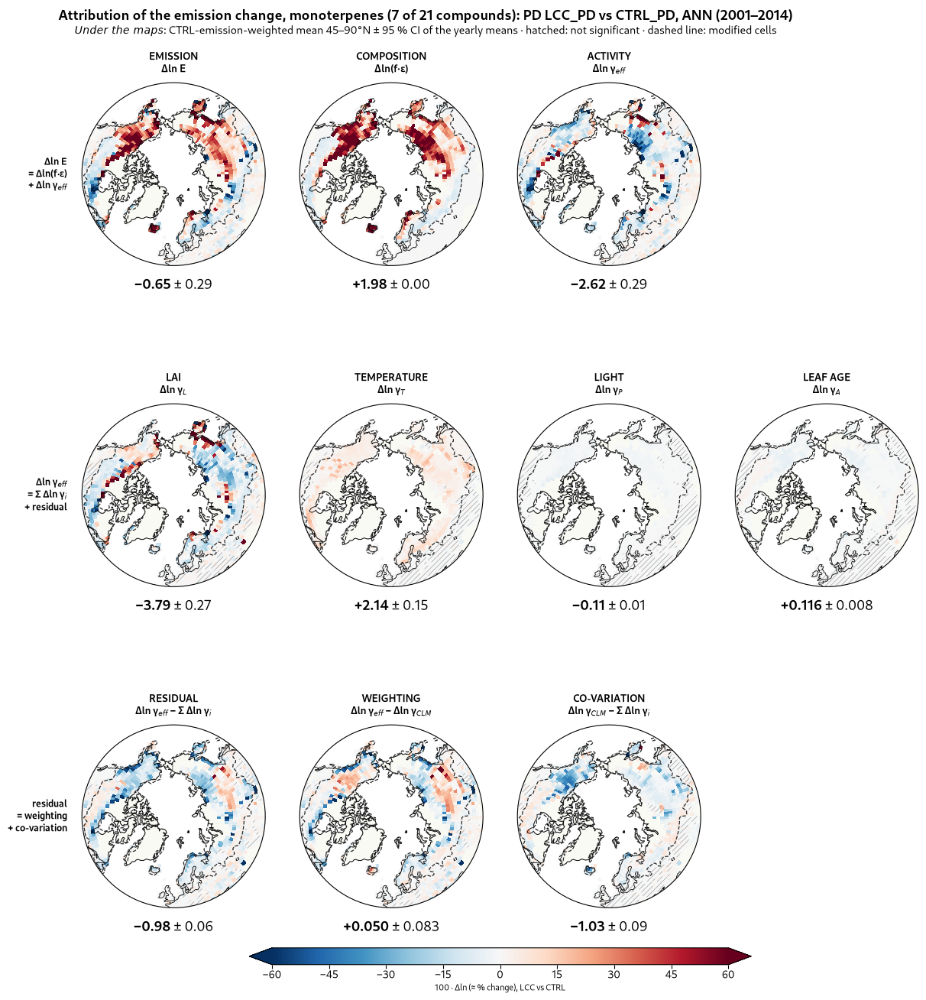

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/FUT_isoprene_factors_ANN_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/FUT_isoprene_attribution_ANN_2001_2014.png


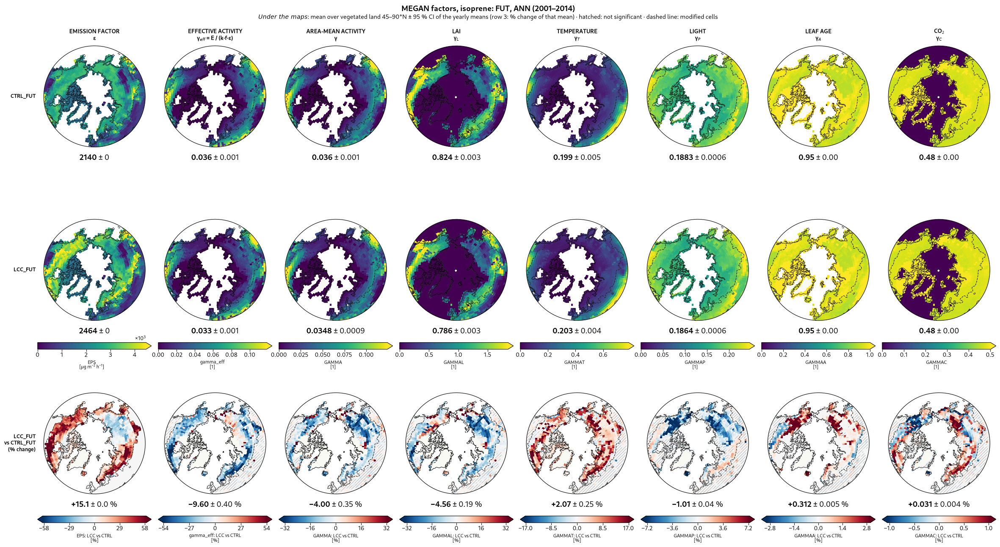

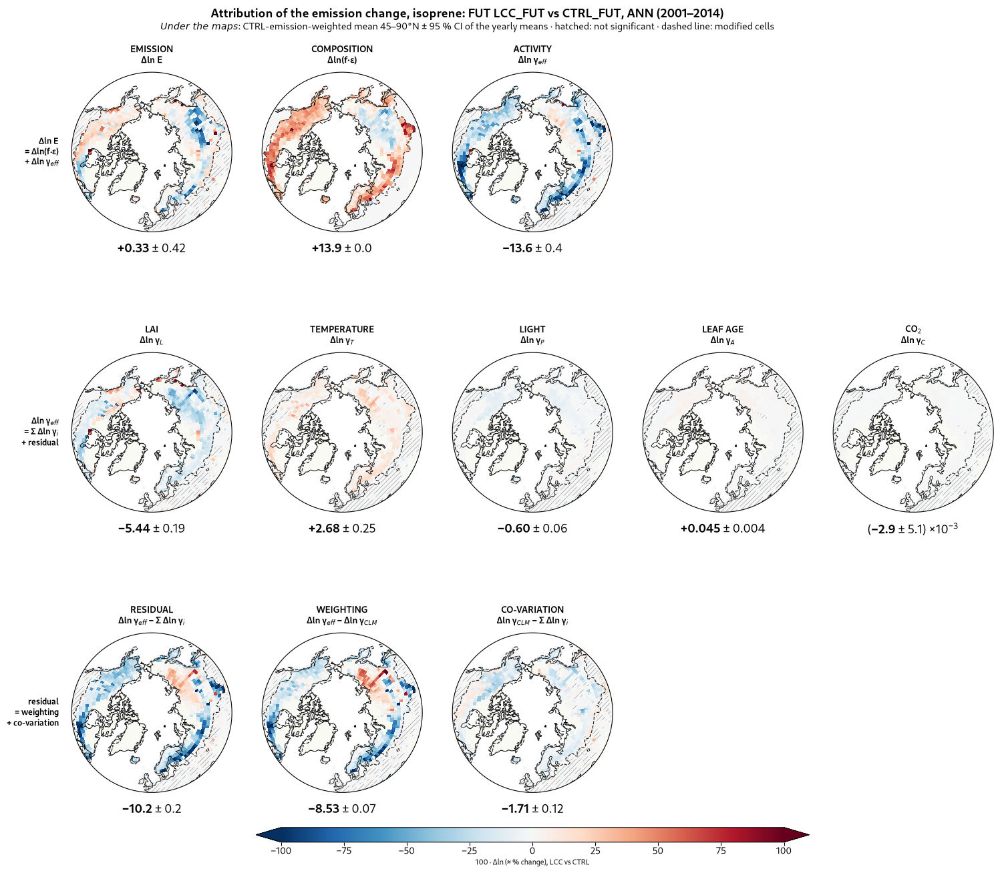

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/FUT_MTERP_factors_ANN_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/FUT_MTERP_attribution_ANN_2001_2014.png


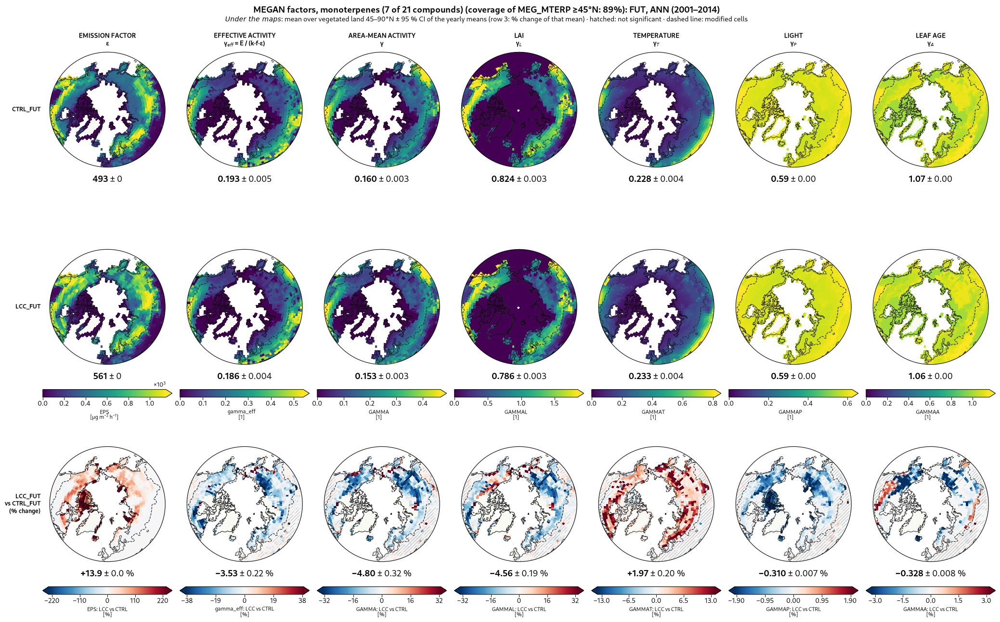

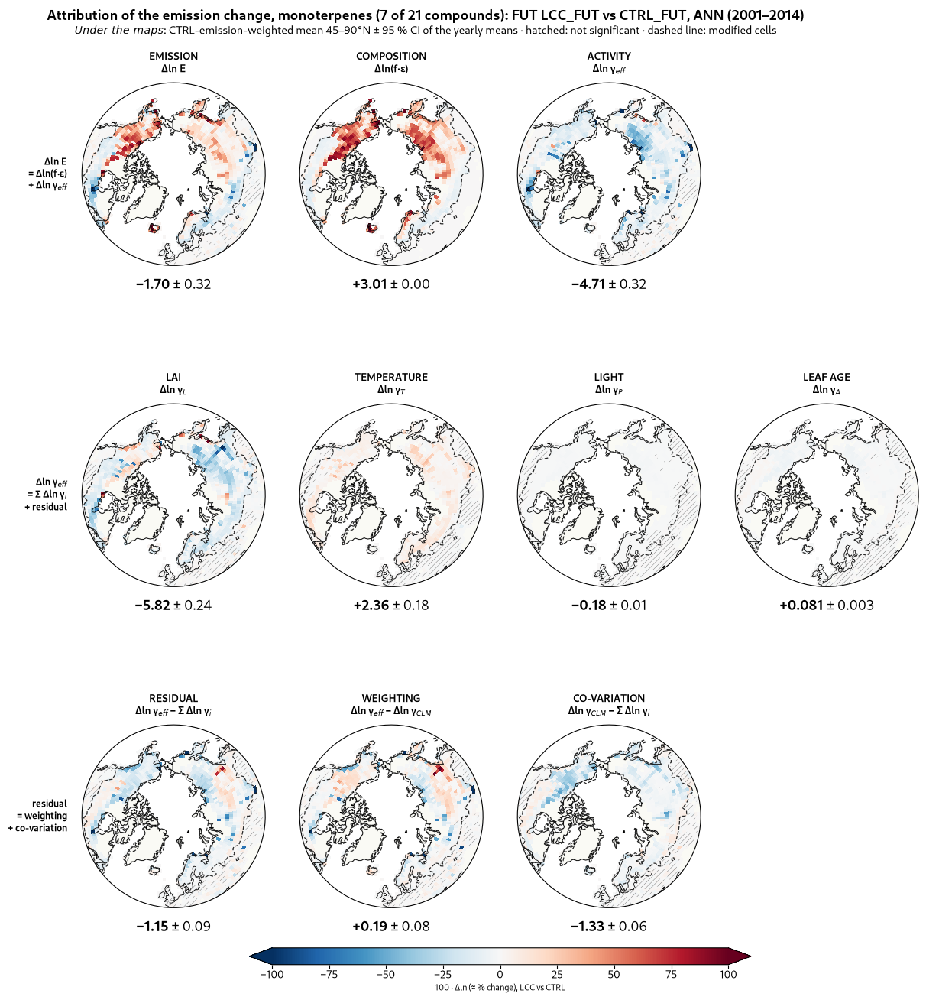

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_isoprene_factors_JJA_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_isoprene_attribution_JJA_2001_2014.png


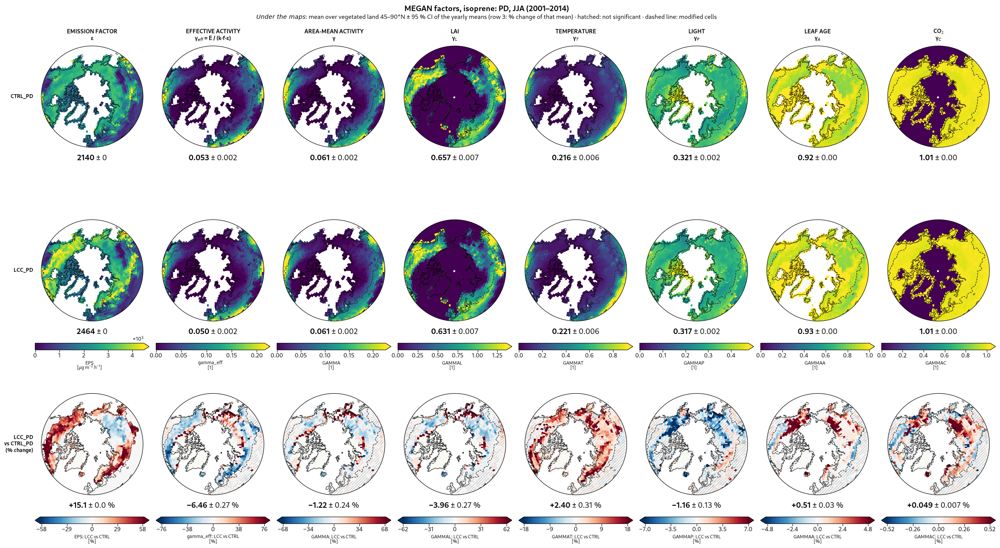

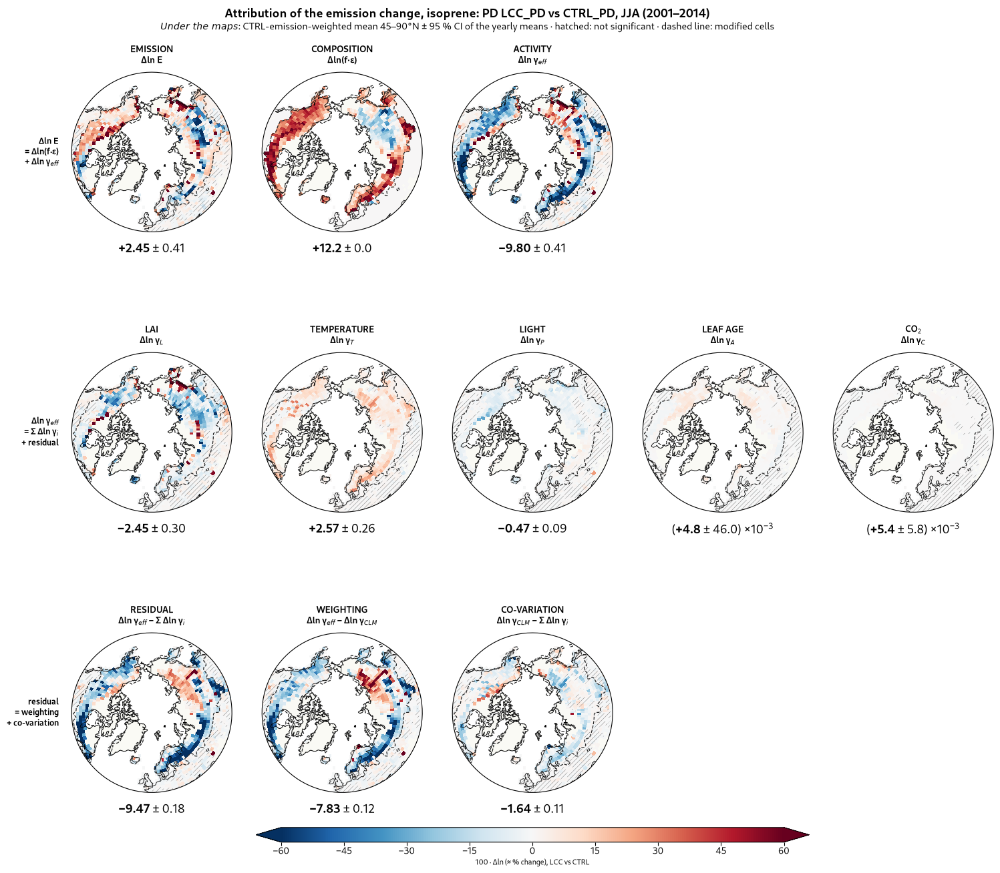

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_MTERP_factors_JJA_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_MTERP_attribution_JJA_2001_2014.png


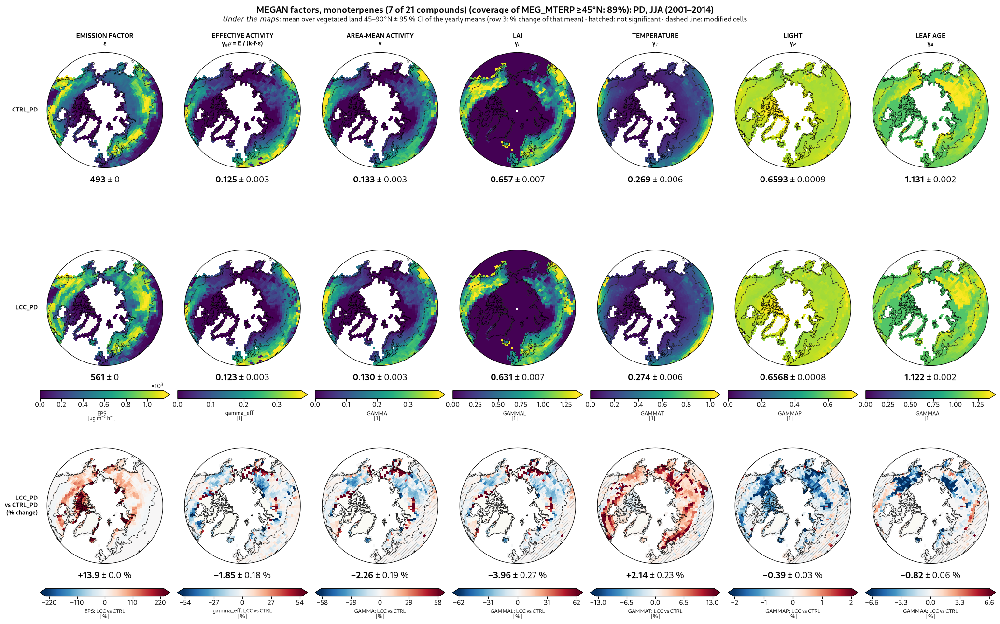

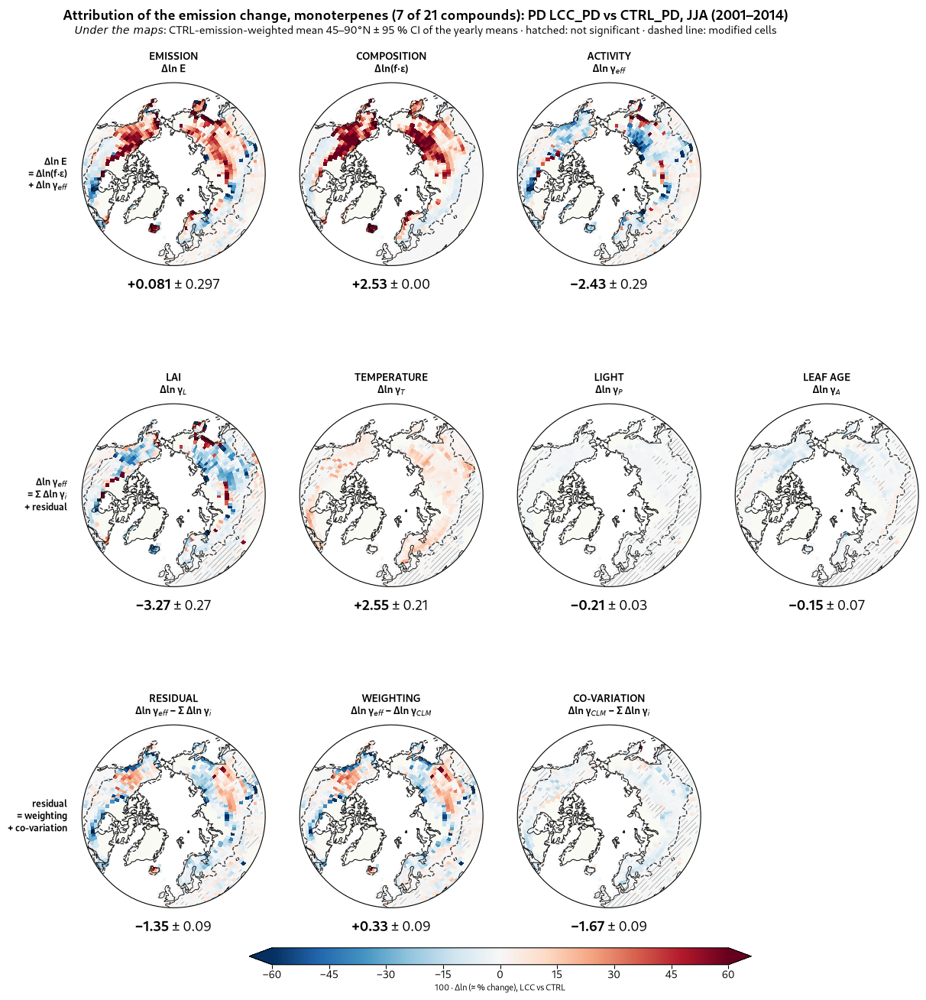

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/FUT_isoprene_factors_JJA_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/FUT_isoprene_attribution_JJA_2001_2014.png


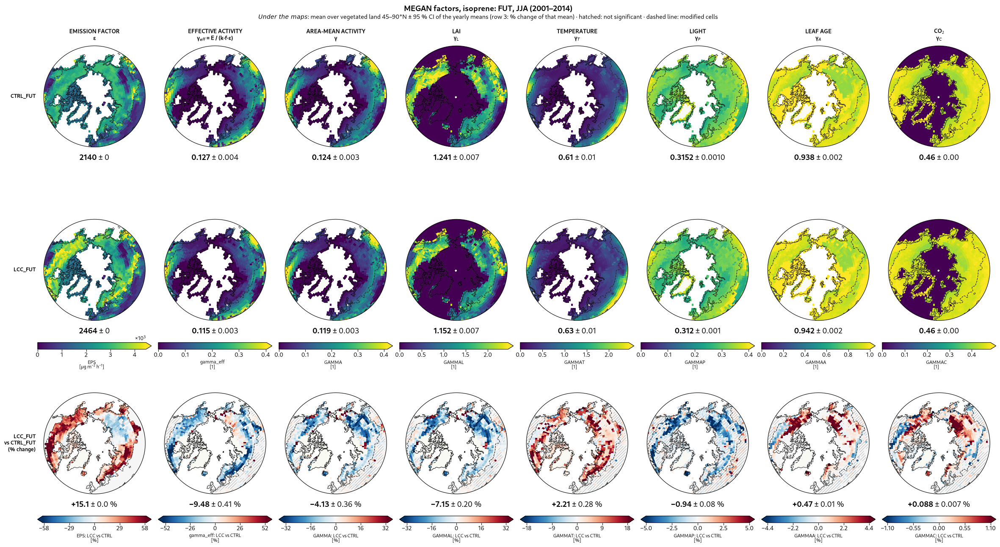

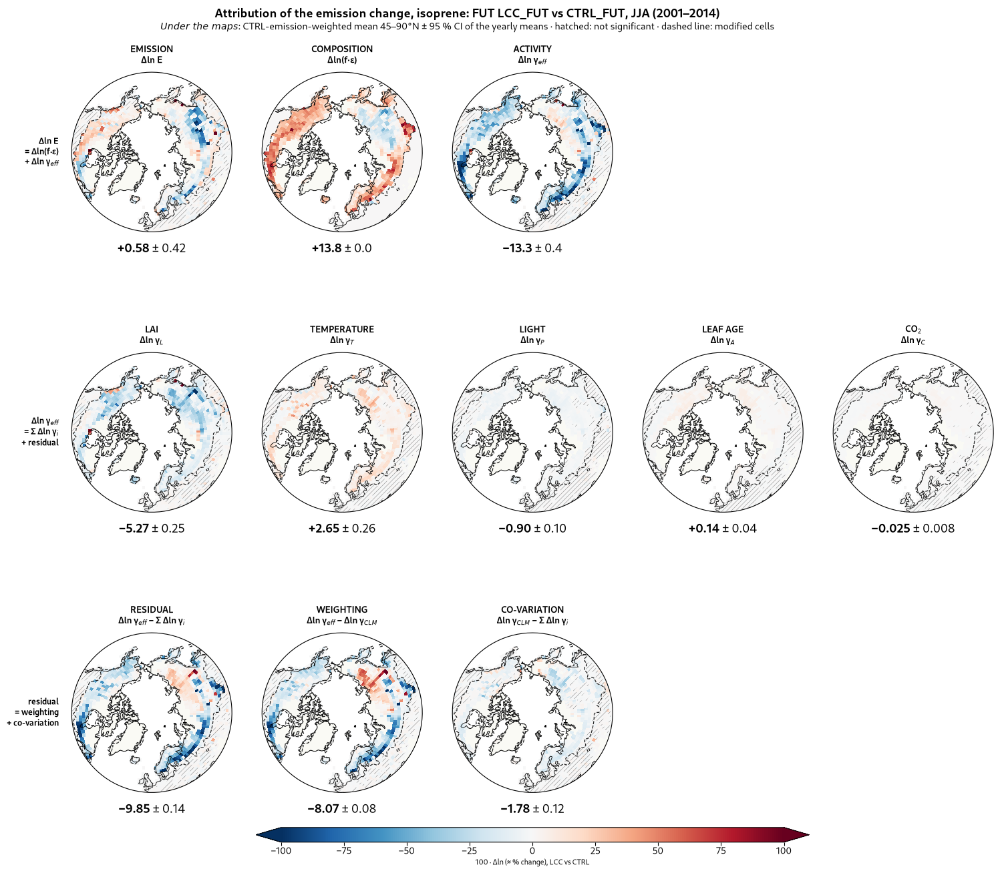

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/FUT_MTERP_factors_JJA_2001_2014.png
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/FUT_MTERP_attribution_JJA_2001_2014.png


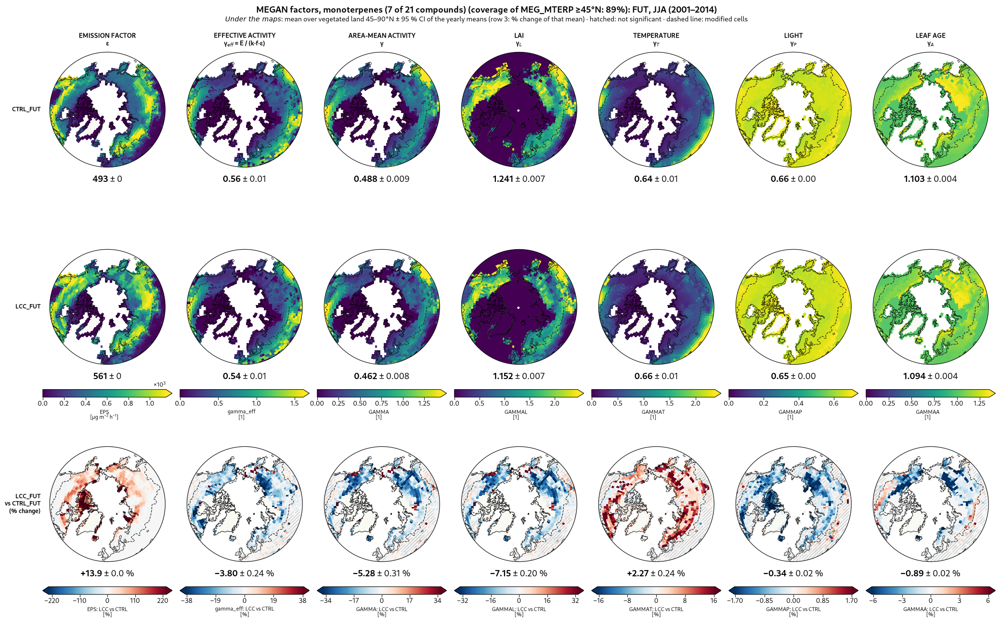

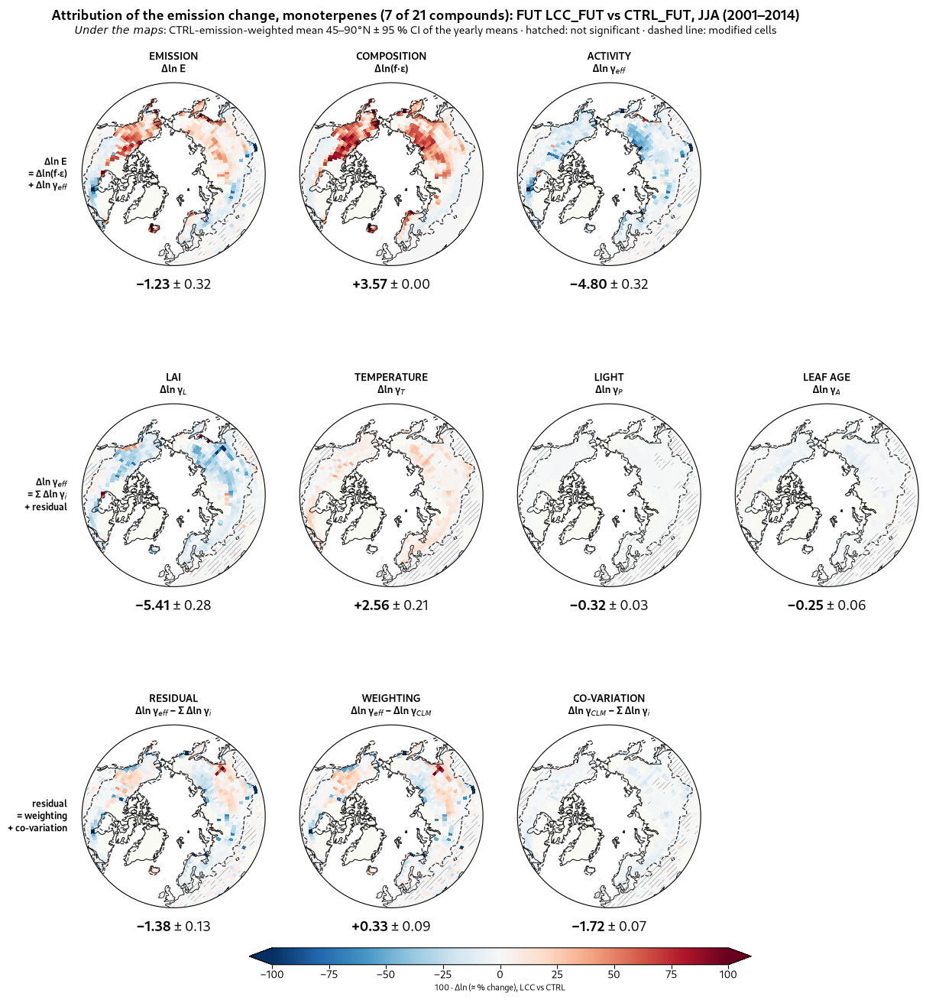

In [4]:
CHANGE_SEASONS = ["ANN", "JJA"]

for season in CHANGE_SEASONS:
    for experiment in ["PD", "FUT"]:
        for group in ["isoprene", "MTERP"]:
            mm.make_factor_maps(group, experiment, season)
            mm.make_attribution_maps(group, experiment, season)
            plt.show()